# ccflowR Parameter Reference Guide

This reference shows how each visual tuning function changes the Sankey object. Each executed example includes a small check against the plot summary or rendered Plotly trace, so the notebook verifies that the parameter changed the intended part of the output.


In [1]:
library(ccflowR)

# Single-condition example data
ex <- example_communication()
data <- ex$data
celltype_colors <- ex$colors

# Multi-condition example data
ex_multi <- example_multinichenet()
data_multi <- ex_multi$data
group_colors <- ex_multi$group_colors

# Parameter examples use package-generated static previews to keep the public
# notebook compact. The plot object is still rendered through ccflowR.
display_sankey <- function(p, width = 600, height = 900, static = TRUE) {
  png_file <- tempfile(fileext = ".png")
  ok <- tryCatch({
    sankey_save(p, png_file, width = width, height = height)
    file.exists(png_file) && file.info(png_file)[["size"]] > 0
  }, error = function(e) {
    message("Static preview failed; displaying interactive widget instead: ", conditionMessage(e))
    FALSE
  })
  if (isTRUE(ok) && requireNamespace("IRdisplay", quietly = TRUE)) {
    IRdisplay::display_png(file = png_file)
  } else {
    sankey_display_notebook(p, width = width, height = height, static = FALSE)
  }
  invisible(p)
}

sankey_trace <- function(p) {
  sankey_render(p)$x$attrs[[1]]
}

check_true <- function(ok, label) {
  if (!isTRUE(ok)) stop("Parameter check failed: ", label, call. = FALSE)
  cat("OK:", label, "\n")
  invisible(TRUE)
}

check_equal <- function(actual, expected, label) {
  ok <- isTRUE(all.equal(actual, expected, check.attributes = FALSE))
  if (!ok) {
    stop("Parameter check failed: ", label,
         " (expected ", paste(expected, collapse = ", "),
         "; got ", paste(actual, collapse = ", "), ")",
         call. = FALSE)
  }
  cat("OK:", label, "\n")
  invisible(TRUE)
}

check_summary_value <- function(p, field, expected, label) {
  check_equal(summary(p)[[field]], expected, label)
}

check_all_link_alpha <- function(p, alpha, label) {
  target <- sprintf(", %.2f)", alpha)
  check_true(all(grepl(target, sankey_trace(p)$link$color, fixed = TRUE)), label)
}

check_any_link_alpha <- function(p, alpha, label) {
  target <- sprintf(", %.2f)", alpha)
  check_true(any(grepl(target, sankey_trace(p)$link$color, fixed = TRUE)), label)
}

check_node_geometry <- function(p, thickness, padding) {
  tr <- sankey_trace(p)
  check_equal(tr$node$thickness, thickness, "node thickness is applied")
  check_equal(tr$node$pad, padding, "node padding is applied")
}

check_render_dimensions <- function(p, width, height) {
  fig <- sankey_render(p)
  check_equal(fig$width, width, "widget width is applied")
  check_equal(fig$height, height, "widget height is applied")
  check_equal(fig$x$layout$width, width, "layout width is applied")
  check_equal(fig$x$layout$height, height, "layout height is applied")
}

check_interactive_filters <- function(p) {
  fig <- sankey_render(p)
  menu_counts <- unlist(lapply(fig$x$layoutAttrs, function(x) {
    if (is.null(x$updatemenus)) 0L else length(x$updatemenus)
  }), use.names = FALSE)
  check_true(any(menu_counts >= 4), "interactive filter dropdowns are rendered")
}


ccflowR v0.1.0 - Cell-Cell Communication Flow Visualization



## Cell Type Colors — `sankey_plot(colors = ...)`

The `colors` parameter accepts a **named character vector** mapping cell type names to hex colors.

| Usage | Description |
|-------|-------------|
| Named vector | Explicit mapping (recommended for publications) |
| `NULL` (default) | Auto-assigned from built-in palette |


OK: custom Macrophage node color is used 


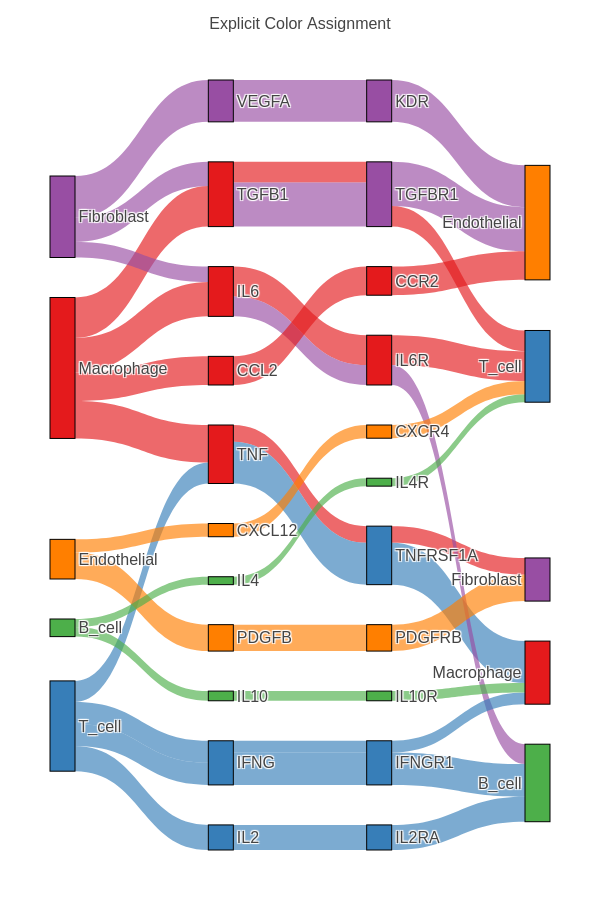

In [2]:
my_colors <- c(
  Macrophage  = "#E41A1C",
  T_cell      = "#377EB8",
  B_cell      = "#4DAF4A",
  Fibroblast  = "#984EA3",
  Endothelial = "#FF7F00"
)

p <- sankey_plot(data, my_colors) +
  sankey_title("Explicit Color Assignment")

check_true(my_colors[["Macrophage"]] %in% sankey_trace(p)$node$color,
           "custom Macrophage node color is used")
display_sankey(p)


## Layer Mode — `sankey_plot(receptor_col = ...)`

| Value | Result |
|-------|--------|
| `"receptor"` (default) | 4-layer: Sender → Ligand → Receptor → Receiver |
| `NULL` | 3-layer: Sender → Ligand → Receiver |


OK: receptor layer is omitted 


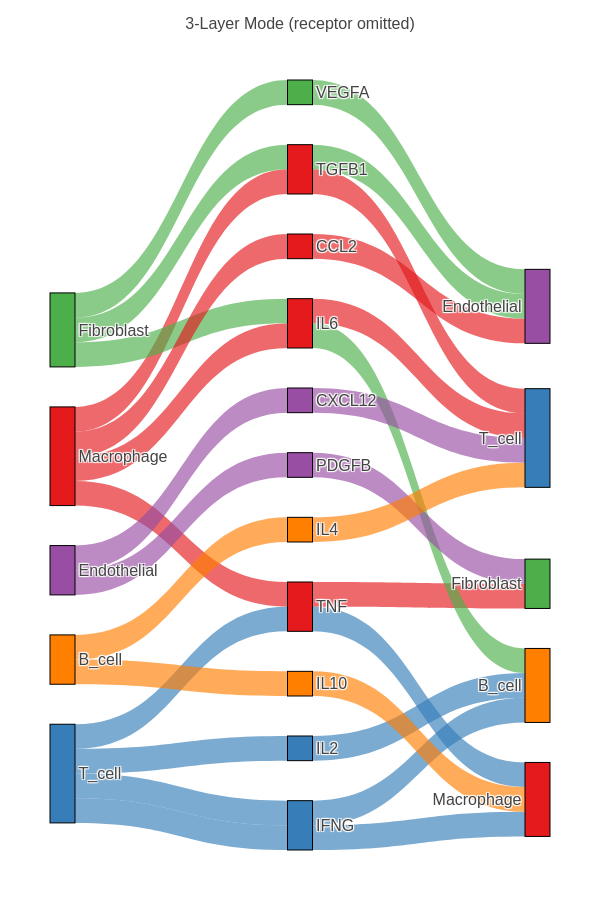

In [3]:
p <- sankey_plot(data, celltype_colors, receptor_col = NULL) +
  sankey_title("3-Layer Mode (receptor omitted)")

check_summary_value(p, "has_receptor", FALSE, "receptor layer is omitted")
display_sankey(p)


## Flow Coloring — `sankey_colors(by = ...)`

| Value | Description |
|-------|-------------|
| `"sender"` (default) | Color flows by sending cell type |
| `"receiver"` | Color flows by receiving cell type |
| `"ligand"` | Color flows by ligand identity |
| `"condition"` | Color flows by experimental group (requires `group_col`) |
| Any color string | Fixed color for all flows (e.g. `"steelblue"`, `"#e74c3c"`) |


OK: flow coloring is set to receiver 


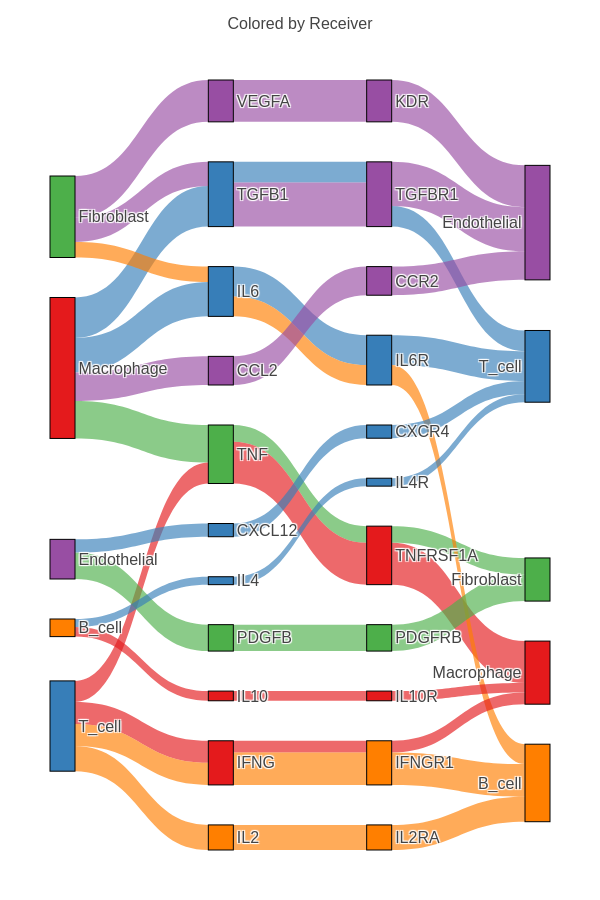

In [4]:
# Color by receiver cell type
p <- sankey_plot(data, celltype_colors) +
  sankey_colors(by = "receiver") +
  sankey_title("Colored by Receiver")

check_summary_value(p, "color_by", "receiver", "flow coloring is set to receiver")
display_sankey(p)


OK: flow coloring is set to condition 


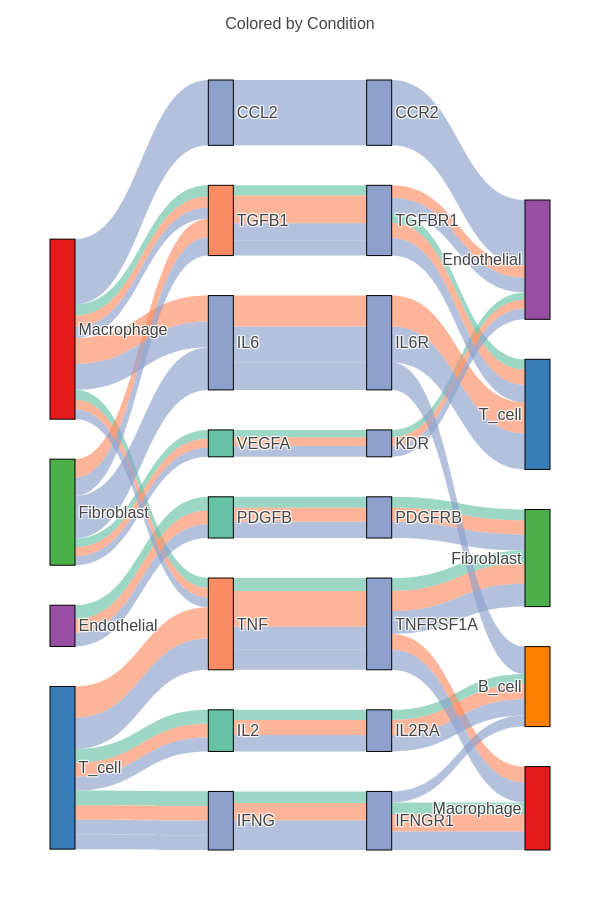

In [5]:
# Color by condition (multi-group data)
p <- sankey_plot(data_multi, celltype_colors, group_col = "group") +
  sankey_colors(by = "condition") +
  sankey_group_colors(group_colors) +
  sankey_title("Colored by Condition")

check_summary_value(p, "color_by", "condition", "flow coloring is set to condition")
display_sankey(p)


## Flow Transparency — `sankey_alpha(value)`

Range: 0 (transparent) to 1 (opaque). Default: `0.65`.

| Value | Use case |
|-------|----------|
| 0.2–0.3 | Subtle, for dense plots with many overlapping flows |
| 0.5–0.65 | Balanced (default range) |
| 0.8–0.9 | Bold, for sparse plots or emphasis |


OK: alpha setting is stored 


OK: all rendered links use alpha = 0.50 


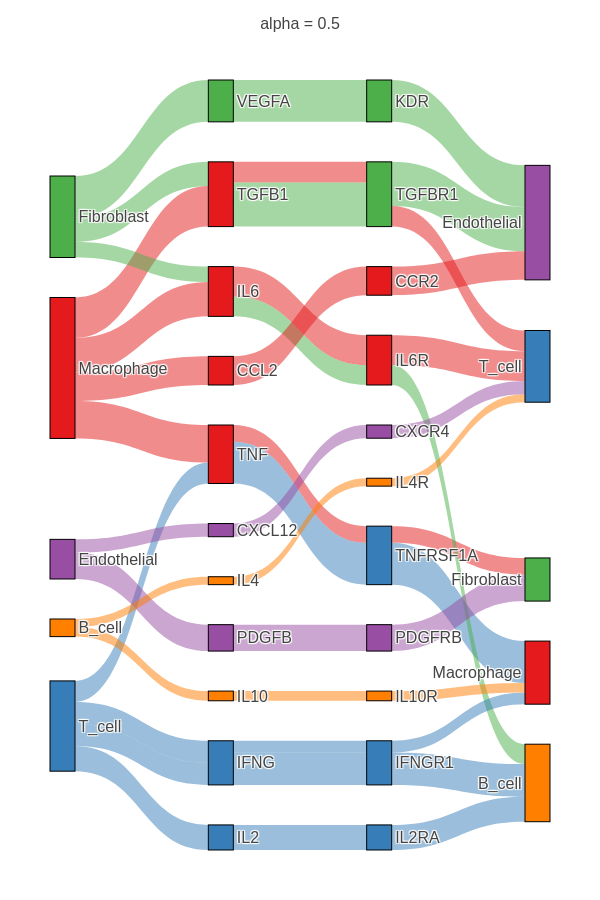

In [6]:
p <- sankey_plot(data, celltype_colors) +
  sankey_alpha(0.5) +
  sankey_title("alpha = 0.5")

check_summary_value(p, "alpha", 0.5, "alpha setting is stored")
check_all_link_alpha(p, 0.5, "all rendered links use alpha = 0.50")
display_sankey(p)


## Pathway Highlighting — `sankey_highlight(...)`

Focus on specific pathways by dimming non-matching flows.

| Parameter | Description |
|-----------|-------------|
| `senders` | Highlight flows from specific sender cell types |
| `ligands` | Highlight flows through specific ligands |
| `receptors` | Highlight flows through specific receptors |
| `receivers` | Highlight flows to specific receiver cell types |
| `dim_alpha` | Transparency of non-highlighted flows (default: 0.1) |

Multiple parameters use **AND** logic — only flows matching all criteria are highlighted.


OK: non-highlighted links are dimmed 


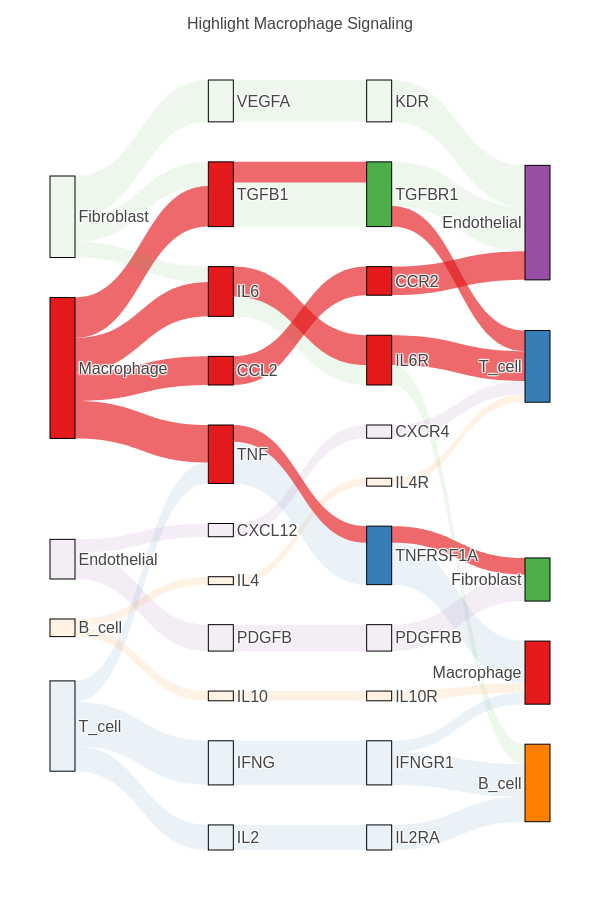

In [7]:
# Highlight specific sender
p <- sankey_plot(data, celltype_colors) +
  sankey_highlight(senders = "Macrophage", dim_alpha = 0.1) +
  sankey_title("Highlight Macrophage Signaling")

check_any_link_alpha(p, 0.1, "non-highlighted links are dimmed")
display_sankey(p)


OK: multi-criterion highlight dims non-matching links 


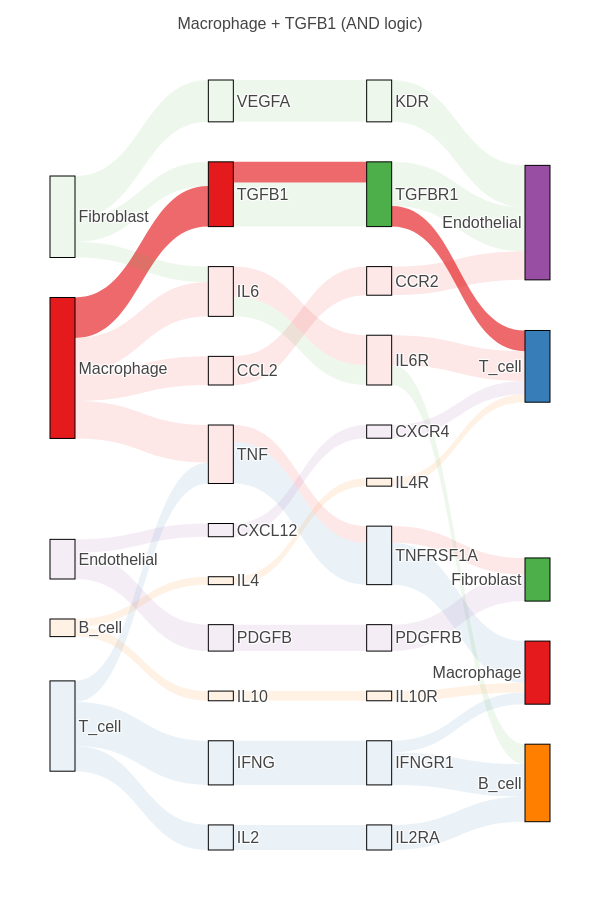

In [8]:
# Combine filters (AND logic)
p <- sankey_plot(data, celltype_colors) +
  sankey_highlight(senders = "Macrophage", ligands = "TGFB1") +
  sankey_title("Macrophage + TGFB1 (AND logic)")

check_any_link_alpha(p, 0.1, "multi-criterion highlight dims non-matching links")
display_sankey(p)


## Node Appearance — `sankey_nodes(thickness, padding, arrangement)`

| Parameter | Description | Default | Range |
|-----------|-------------|---------|-------|
| `thickness` | Node bar width (px) | 20 | 5–50 |
| `padding` | Vertical spacing (px) | 30 | 10–100 |
| `arrangement` | `"fixed"` or `"snap"` (draggable) | `"fixed"` | — |


OK: node thickness is applied 
OK: node padding is applied 


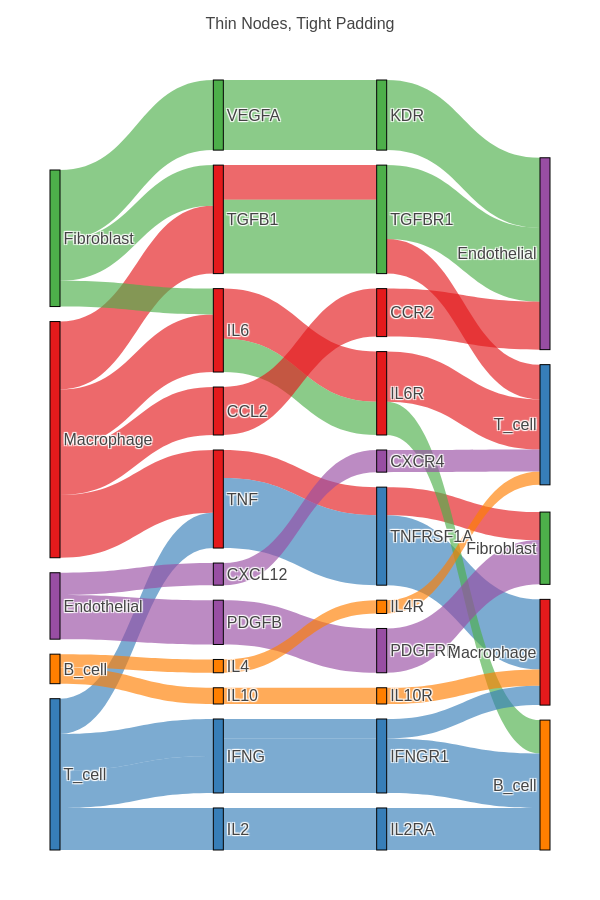

In [9]:
p <- sankey_plot(data, celltype_colors) +
  sankey_nodes(thickness = 10, padding = 15) +
  sankey_title("Thin Nodes, Tight Padding")

check_node_geometry(p, thickness = 10, padding = 15)
display_sankey(p)


## Node Order — `sankey_order(...)`

By default, nodes are ordered by an activity-weighted barycenter heuristic. Use `sankey_order()` to set explicit vertical positions.

| Parameter | Description |
|-----------|-------------|
| `senders` | Order of sender nodes (top to bottom) |
| `ligands` | Order of ligand nodes |
| `receptors` | Order of receptor nodes |
| `receivers` | Order of receiver nodes |


OK: custom order locks the arrangement 


OK: custom order creates explicit node positions 


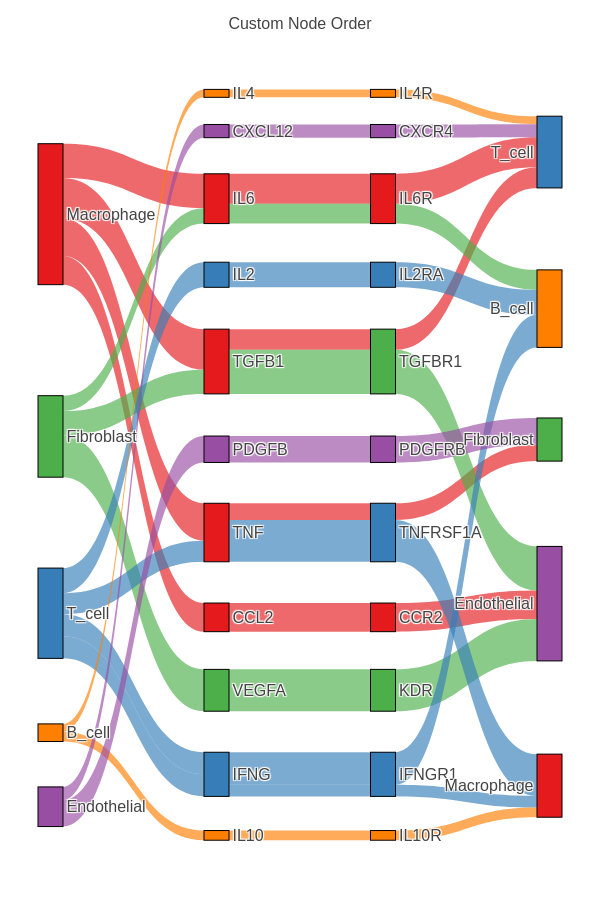

In [10]:
p <- sankey_plot(data, celltype_colors) +
  sankey_order(
    senders = c("Macrophage", "Fibroblast", "T_cell", "B_cell", "Endothelial"),
    receivers = c("T_cell", "B_cell", "Fibroblast", "Endothelial", "Macrophage")
  ) +
  sankey_title("Custom Node Order")

tr <- sankey_trace(p)
check_equal(tr$arrangement, "fixed", "custom order locks the arrangement")
check_true(!is.null(tr$node$x) && !is.null(tr$node$y),
           "custom order creates explicit node positions")
display_sankey(p)


## Labels — `sankey_labels(size)`

Default size: `12`. Range: 8–24.

| Size | Use case |
|------|----------|
| 8–10 | Dense plots, many nodes |
| 12 | Default, good for screen and standard figures |
| 16–24 | Presentations, posters |


OK: label size is applied 


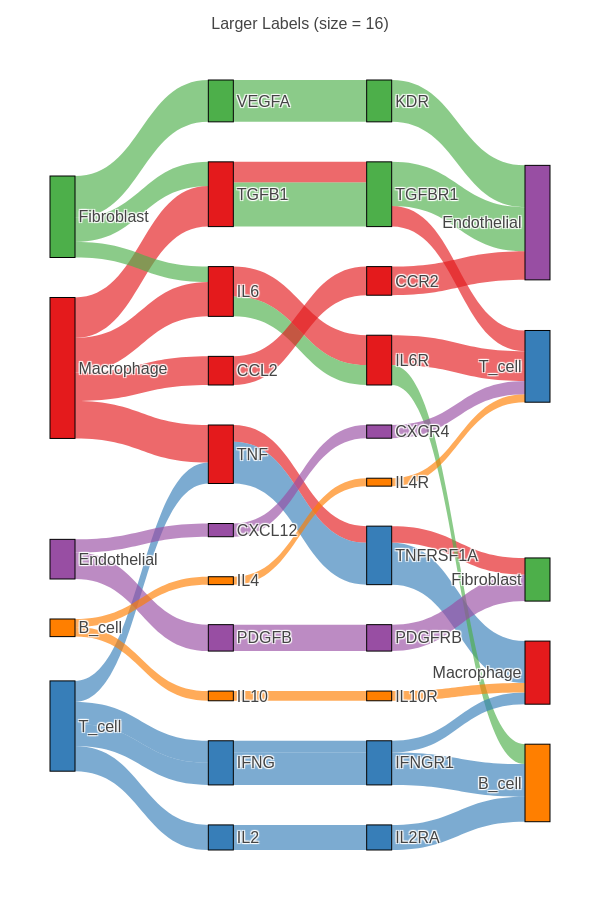

In [11]:
p <- sankey_plot(data, celltype_colors) +
  sankey_labels(size = 16) +
  sankey_title("Larger Labels (size = 16)")

check_equal(sankey_trace(p)$textfont$size, 16, "label size is applied")
display_sankey(p)


## Interactive Filters — `sankey_interactive()`

Adds dropdown menus for sender, ligand, receptor, and receiver filtering directly in the plot.


OK: interactive filter dropdowns are rendered 


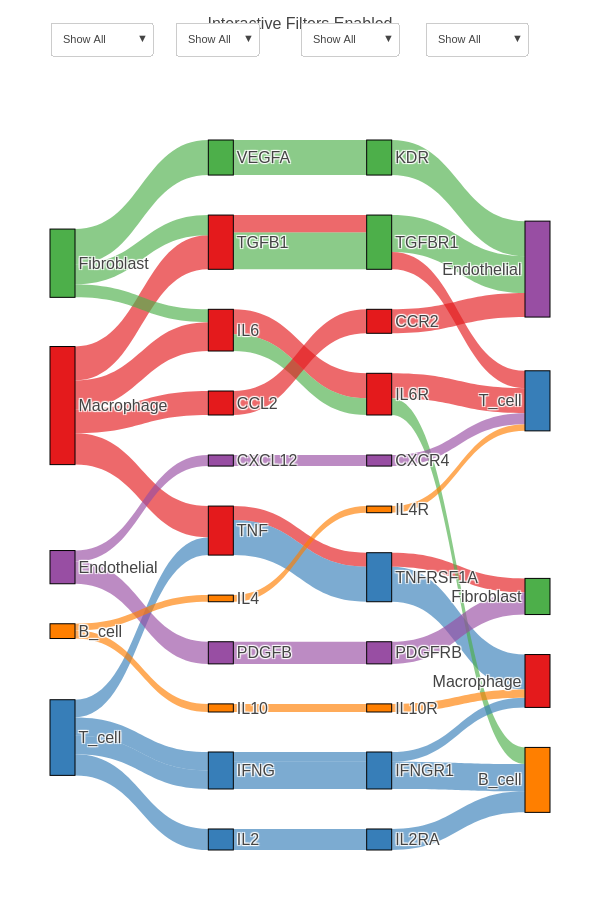

In [12]:
p <- sankey_plot(data, celltype_colors) +
  sankey_interactive() +
  sankey_title("Interactive Filters Enabled")

check_interactive_filters(p)
display_sankey(p)


## Ligand/Receptor Node Colors — `sankey_node_colors(mode)`

| Value | Description |
|-------|-------------|
| `"cell_type"` (default) | Nodes colored by their primary associated cell type |
| `"weighted_mix"` | Nodes colored by weighted blend of all connected cell types |


OK: weighted node coloring returns one color per node 


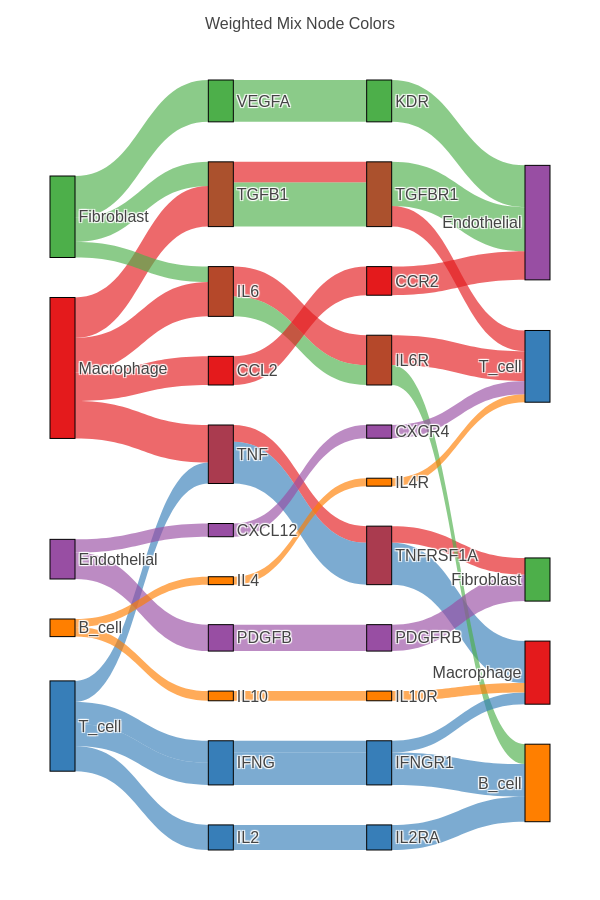

In [13]:
p <- sankey_plot(data, celltype_colors) +
  sankey_node_colors("weighted_mix") +
  sankey_title("Weighted Mix Node Colors")

tr <- sankey_trace(p)
check_equal(length(tr$node$color), length(tr$node$label),
            "weighted node coloring returns one color per node")
display_sankey(p)


## Layout & Dimensions — `sankey_layout(width, height)`

Default: `600 × 900` pixels (portrait orientation, good for 4-layer Sankey).

| Dimensions | Use case |
|------------|----------|
| 600×900 | Default, standard figures |
| 800×500 | Wide, for 3-layer or fewer nodes |
| 400×1000 | Tall, for many nodes |


OK: widget width is applied 
OK: widget height is applied 
OK: layout width is applied 
OK: layout height is applied 


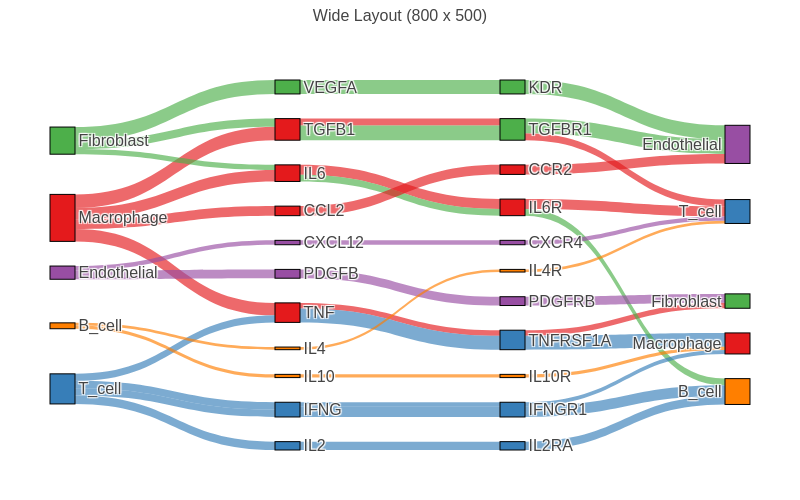

In [14]:
p <- sankey_plot(data, celltype_colors) +
  sankey_layout(width = 800, height = 500) +
  sankey_title("Wide Layout (800 x 500)")

check_render_dimensions(p, width = 800, height = 500)
display_sankey(p, width = 800, height = 500)


## Orientation — `sankey_orientation(direction)`

| Value | Description |
|-------|-------------|
| `"horizontal"` (default) | Left-to-right flow |
| `"vertical"` | Top-to-bottom flow |


OK: vertical orientation is applied 


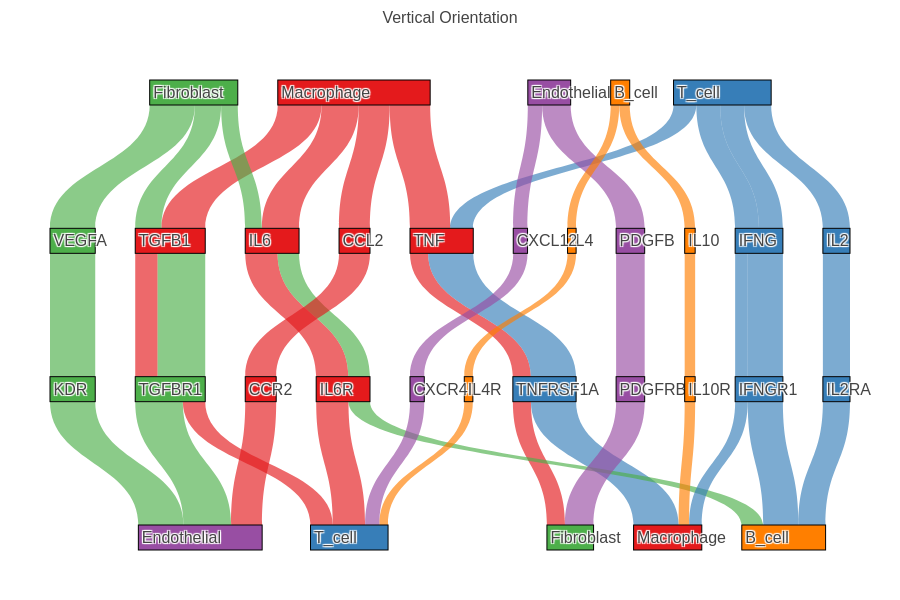

In [15]:
p <- sankey_plot(data, celltype_colors) +
  sankey_orientation("vertical") +
  sankey_layout(width = 900, height = 600) +
  sankey_title("Vertical Orientation")

check_equal(sankey_trace(p)$orientation, "v", "vertical orientation is applied")
display_sankey(p, width = 900, height = 600)


## Cosmetic Parameters

These parameters control visual styling. Defaults work well for most cases.

### `sankey_title(title, size)`
Add a plot title. Default size: `16`. Use `size = 24` for posters, `size = 10` for compact figures.

### `sankey_margins(left, right, top, bottom)`
Set plot margins in pixels. Defaults: `left=50, right=50, top=80, bottom=50`. Increase margins if labels are clipped.

### `sankey_background(paper, plot)`
Set background colors. Both default to `"white"`. Use `"#F0F0F0"` for light gray or `"#1a1a1a"` for dark mode.

### `sankey_font(family, size)`
Set font properties. Default: `family="Arial", size=12`. Use `"Times New Roman"` for journals requiring serif fonts.

### `sankey_legend(show, title)`
Control legend visibility. Default: `show=TRUE`. Hide with `show=FALSE` for minimal figures; add a custom title with `title="Cell Types"`.


## Group Colors — `sankey_group_colors(colors)`

Set colors for experimental conditions. Used with `sankey_colors(by = "condition")`.

```r
group_colors <- c(Control = "#2196F3", Treatment = "#FF5722", Disease = "#4CAF50")

p <- sankey_plot(data, celltype_colors, group_col = "group") +
  sankey_colors(by = "condition") +
  sankey_group_colors(group_colors)
```


OK: group color mapping is applied through condition coloring 


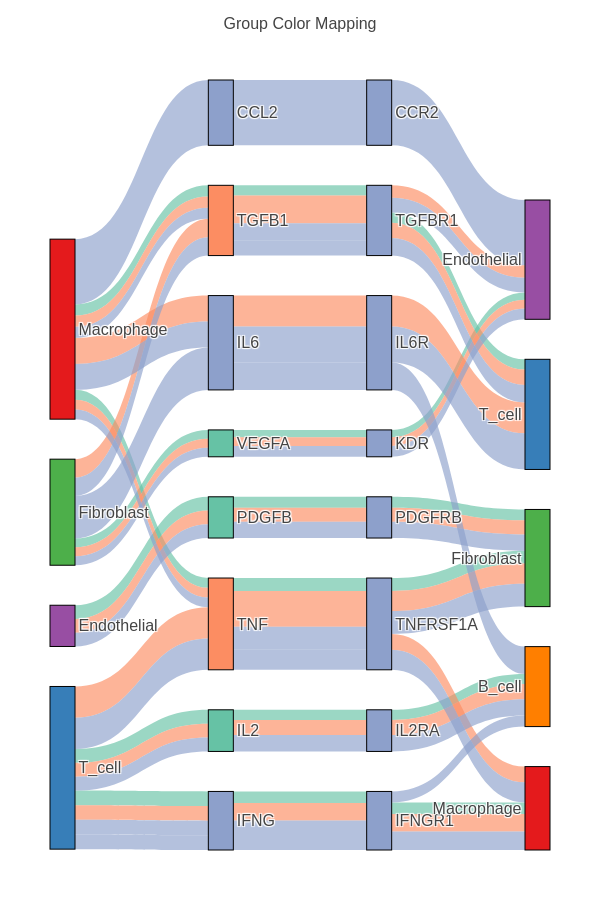

In [16]:
p <- sankey_plot(data_multi, celltype_colors, group_col = "group") +
  sankey_colors(by = "condition") +
  sankey_group_colors(group_colors) +
  sankey_title("Group Color Mapping")

check_summary_value(p, "color_by", "condition", "group color mapping is applied through condition coloring")
display_sankey(p)


## Saving Plots — `sankey_save(plot, filename, ...)`

Format is auto-detected from the file extension.

| Format | Extension | Notes |
|--------|-----------|-------|
| HTML | `.html` | Interactive, always works |
| PNG | `.png` | Requires kaleido or webshot2 |
| PDF | `.pdf` | Requires kaleido or webshot2 |
| SVG | `.svg` | Requires kaleido or chromote |

```r
sankey_save(p, "figure.html")                          # interactive HTML
sankey_save(p, "figure.png", width = 700, height = 900) # static PNG
sankey_pdf(p, "figure.pdf")                             # convenience wrapper
```


## Quick Reference

| Function | Key Parameters | Default |
|----------|---------------|---------|
| `sankey_plot()` | `colors`, `receptor_col`, `group_col` | 4-layer |
| `sankey_colors()` | `by` | `"sender"` |
| `sankey_alpha()` | `value` | `0.65` |
| `sankey_highlight()` | `senders`, `ligands`, `receptors`, `receivers`, `dim_alpha` | dim_alpha=0.1 |
| `sankey_nodes()` | `thickness`, `padding`, `arrangement` | 20, 30, fixed |
| `sankey_order()` | `senders`, `ligands`, `receptors`, `receivers` | auto (barycenter) |
| `sankey_labels()` | `size` | 12 |
| `sankey_interactive()` | — | — |
| `sankey_node_colors()` | `mode` | `"cell_type"` |
| `sankey_layout()` | `width`, `height` | 600, 900 |
| `sankey_title()` | `title`, `size` | size=16 |
| `sankey_margins()` | `left`, `right`, `top`, `bottom` | 50, 50, 80, 50 |
| `sankey_background()` | `paper`, `plot` | white, white |
| `sankey_font()` | `family`, `size` | Arial, 12 |
| `sankey_orientation()` | `direction` | `"horizontal"` |
| `sankey_legend()` | `show`, `title` | TRUE, NULL |
| `sankey_group_colors()` | `colors` | — |
| `sankey_save()` | `filename`, `width`, `height`, `scale` | — |


## Troubleshooting

| Issue | Solution |
|-------|----------|
| "Missing required columns" | Check column names: `sender`, `receiver`, `ligand`, `receptor` |
| Plot not displaying | Select the `ccflowR R` kernel; use `sankey_display_notebook(p)` in Jupyter |
| Flows all same thickness | Check that expression columns exist; otherwise defaults to uniform |
| Colors not applied | Ensure color vector names match cell type names exactly |
| Group coloring not working | Pass `group_col = "group"` to `sankey_plot()` |
